In [3]:
"""
2D implementation of 
∂t phi_a= ∂x [D ∂x phi_a + phi_a(1-phi_a-phi_b)∂x pi_a +  sqrt(2D phi_a(1-phi_a-phi_b)) Z]
∂t phi_b= ∂x [D ∂x phi_b + phi_b(1-phi_a-phi_b)∂x pi_b +  sqrt(2D phi_b(1-phi_a-phi_b)) Z]
using a conservative finite-volume discretization and a stochastic (predictor-corrector) time integrator.

Features:
- Positivity floor for density
- multiplicative conservative noise (phi_a(1-ph i_a-phi_b))
- Can be extended to the case with convolutional interaction potential using FFT (periodic)

Author: Tuan Pham and Wout Merbis
"""
import numpy as np
import matplotlib.pyplot as plt
from numpy.fft import rfft, irfft
from matplotlib.animation import FuncAnimation, PillowWriter
import fhd
import importlib
import time
from scipy.interpolate import interp1d
from scipy.optimize import minimize
from fhd.structure_factor import *

importlib.reload(fhd)


import os
os.environ["NUMBA_THREADING_LAYER"] = "omp"

import numba as nb


# Interface mixing due to voter mechanism

In [4]:
N = (2**7, 2**7)
L = (50,50)
Lx, Ly = L
sim_2d = fhd.fhd_2d(L,N, bc= 'Neumann', fft=False, 
                    schelling_flux="finite_volume",
                    projection_mode="redistribute" , 
                    use_numba_projection=True, 
                    numba_projection_threads=1,
                    voter_noise_mode="wright_fisher",
                    wf_gaussian_threshold=0.01)
# sim_dcm = fhd.fhd_2d(L,N, bc= 'Neumann', fft=False, 
#                     schelling_flux="finite_volume",
#                     projection_mode="redistribute" , 
#                     use_numba_projection=True, 
#                     numba_projection_threads=1,
#                     voter_noise_mode="dcm",
#                     wf_gaussian_threshold=0.025)
# sim_wf.set_seed(1234)
# sim_wfg.set_seed(1234)
sim_2d.set_seed(1234)


/home/wmrs@cbsp.nl/codebase/fluctuating_hydro/.venv/lib/python3.10/site-packages/numba/np/ufunc/parallel.py:373: NumbaWarning: The TBB threading layer requires TBB version 2021 update 6 or later i.e., TBB_INTERFACE_VERSION >= 12060. Found TBB_INTERFACE_VERSION = 12050. The TBB threading layer is disabled.
  warnings.warn(problem)


In [5]:
regimes = ["segregating", "integrating", "migrating", "well-mixed"]
kappas = [np.array([[0.6, -0.4],[-0.4, 0.6]]), np.array([[0.6, 1], [1, 0.6]]),
np.array([[1, 1], [-1, 1]]), np.array([[0, 0], [0, 0]])]


h = 0.01
D = 0.1*np.ones(2) # Schelling diffusion coefficient
Gamma = kappas[0]/2 # Utility nabla^3 term coefficient
D_v = 0.1  #Voter model diffusion term
beta = 10

param = {'D': D, 'kappa': kappas[0], 'Gamma': Gamma, 'D_v': D_v, 'beta': beta, 'h' : h}

x = sim_2d.x
y = sim_2d.y

xx, yy = np.meshgrid(x, y, indexing='ij')
nspecies = sim_2d.nspecies

np.random.default_rng(1234)

phi = np.zeros((nspecies,)+ N)
phi0 = 0.4
# pert_amp = 0.0
# noise_amp = 0.05
phi[0] = phi0* (1 +  np.tanh(yy))  
phi[1] = phi0*  (1 -  np.tanh(yy)) 
# phi = sim_2d.project_density_fast(phi)

# phi = np.load(f"data/runs/run_T04_D{D[0]:.2f}_Dv{D_v:.2f}_noise.npy")[:,-1,:,:]

Initial conditions for the interface


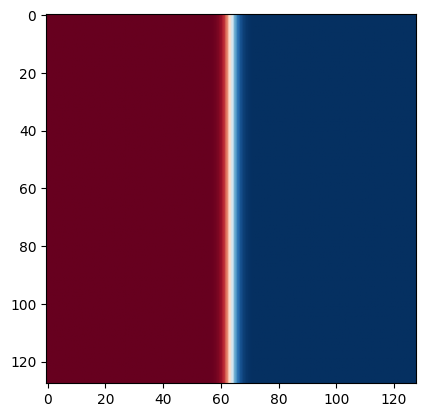

In [5]:
print("Initial conditions for the interface")
plt.imshow(phi[0]-phi[1], cmap = 'RdBu')
plt.show()

# Evolve tanh initial conditions without voter (pure Schelling)

Step 1000/500000: mean rho = 0.400000, min = 0.000000e+00, D_index = 0.984073, mean_kl_div = 0.501330
Step 2000/500000: mean rho = 0.400000, min = 0.000000e+00, D_index = 0.988852, mean_kl_div = 0.502117
Step 3000/500000: mean rho = 0.400000, min = 0.000000e+00, D_index = 0.993401, mean_kl_div = 0.503009
Step 4000/500000: mean rho = 0.400000, min = 0.000000e+00, D_index = 0.997956, mean_kl_div = 0.503995
Step 5000/500000: mean rho = 0.400000, min = 0.000000e+00, D_index = 1.001950, mean_kl_div = 0.505024
Step 6000/500000: mean rho = 0.400000, min = 0.000000e+00, D_index = 1.005802, mean_kl_div = 0.506082
Step 7000/500000: mean rho = 0.400000, min = 0.000000e+00, D_index = 1.009791, mean_kl_div = 0.507194
Step 8000/500000: mean rho = 0.400000, min = 0.000000e+00, D_index = 1.013614, mean_kl_div = 0.508314
Step 9000/500000: mean rho = 0.400000, min = 0.000000e+00, D_index = 1.017260, mean_kl_div = 0.509464
Step 10000/500000: mean rho = 0.400000, min = 0.000000e+00, D_index = 1.020895, me

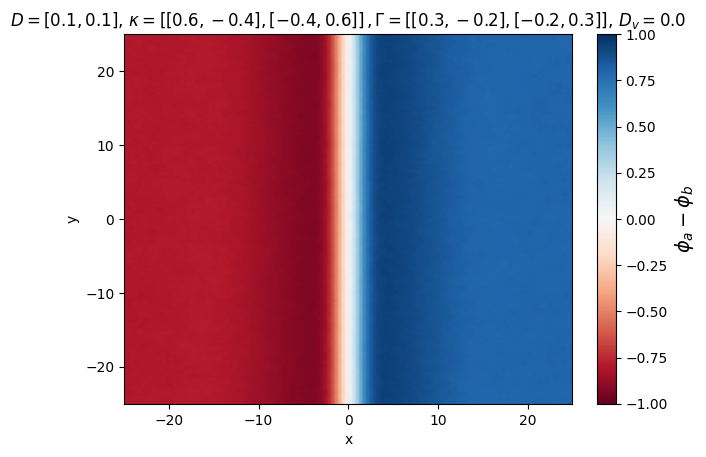

Simulation ran in t = 2021.184539 seconds


In [6]:
dt = 1e-3
nsteps = 500_000
noise = True
frames = 500

param["D_v"] = 0.0

st = time.time()
phi_run = sim_2d.run(phi, param, nsteps, dt, noise, frames, scheme = "FE", model = "Vitelli", use_fastpath=False, verbatum = True)
et = time.time()
print(f"Simulation ran in t = {et-st:.6f} seconds")


In [7]:
np.save('data/runs/Schelling_seg_interface', phi_run)

# Evolve exactly the same initial conditions with Voter interactions

Wright-Fisher Voter noise: tau=0.00524288
  sampler: Griffiths Gaussian
  E[M] ~ 381.970
  std[M] ~ 11.276
Step 1000/500000: mean rho = 0.400000, min = 0.000000e+00, D_index = 1.001986, mean_kl_div = 0.510241
Step 2000/500000: mean rho = 0.400000, min = 0.000000e+00, D_index = 1.005803, mean_kl_div = 0.509900
Step 3000/500000: mean rho = 0.400000, min = 0.000000e+00, D_index = 1.009913, mean_kl_div = 0.510279
Step 4000/500000: mean rho = 0.400000, min = 0.000000e+00, D_index = 1.017237, mean_kl_div = 0.513330
Step 5000/500000: mean rho = 0.400000, min = 0.000000e+00, D_index = 1.019816, mean_kl_div = 0.514378
Step 6000/500000: mean rho = 0.400000, min = 0.000000e+00, D_index = 1.020306, mean_kl_div = 0.512830
Step 7000/500000: mean rho = 0.400000, min = 0.000000e+00, D_index = 1.024001, mean_kl_div = 0.514300
Step 8000/500000: mean rho = 0.400000, min = 0.000000e+00, D_index = 1.028143, mean_kl_div = 0.515928
Step 9000/500000: mean rho = 0.400000, min = 0.000000e+00, D_index = 1.032929

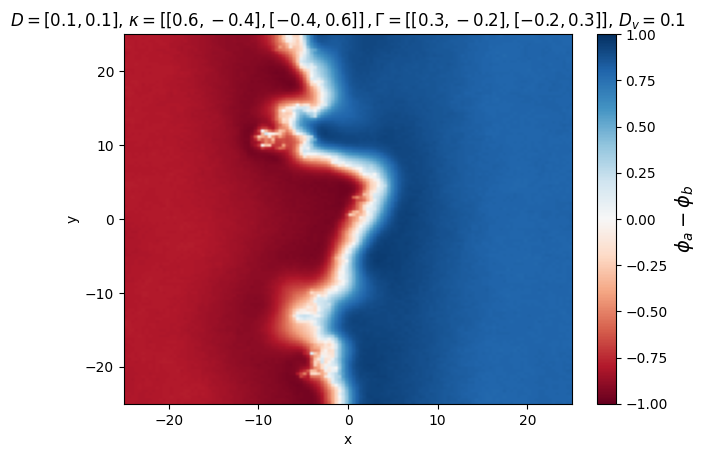

Simulation ran in t = 3009.031609 seconds


In [8]:
# dt = 1e-3
# nsteps = 500_000
# noise = True
# frames = 500

param["D_v"] = 0.1

st = time.time()
phi_run_vot = sim_2d.run(phi, param, nsteps, dt, noise, frames, scheme = "FE", model = "Schelling+Voter", use_fastpath=False, verbatum = True)
et = time.time()
print(f"Simulation ran in t = {et-st:.6f} seconds")


In [9]:
np.save('data/runs/Schelling+Voter_seg_interface', phi_run_vot)


# Plot configurational results

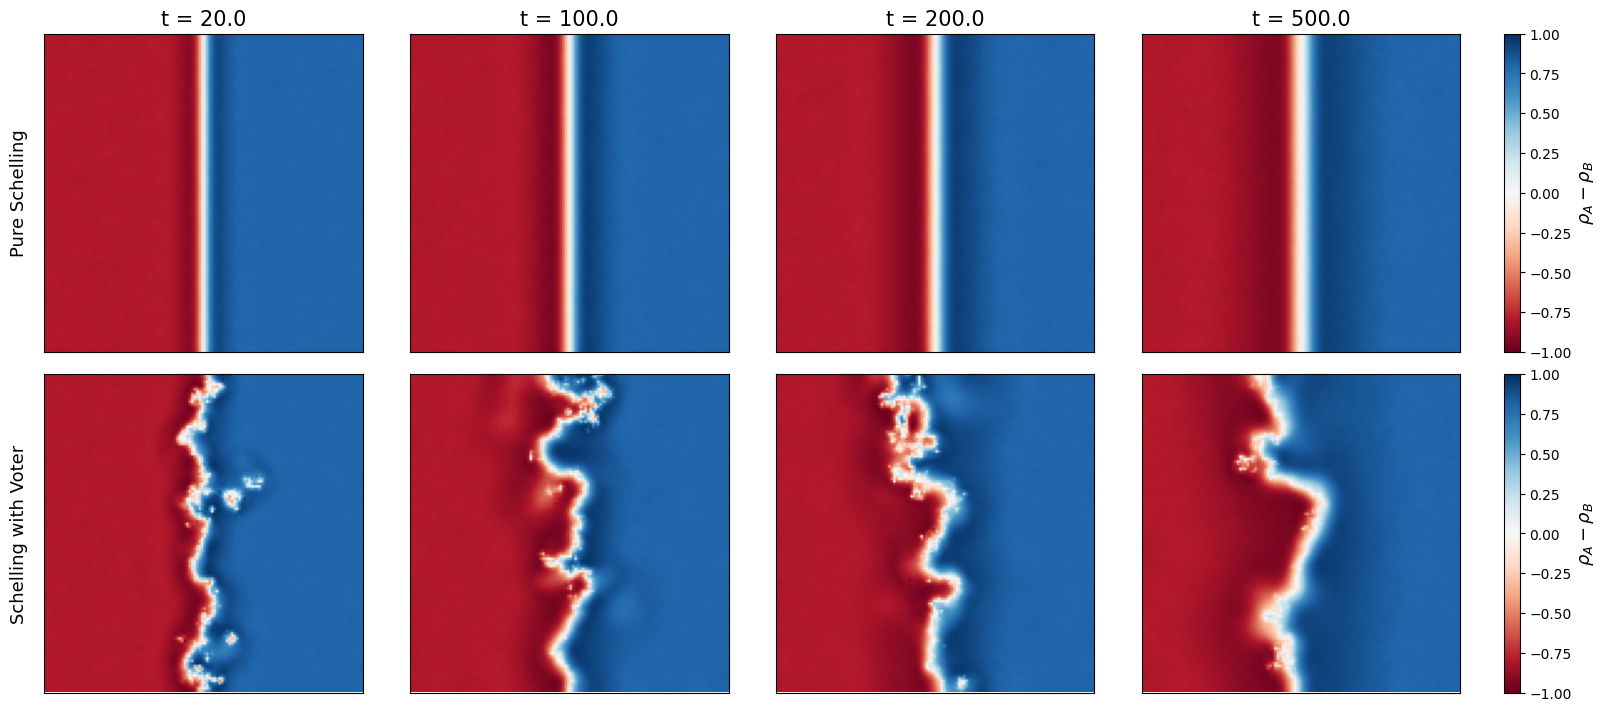

In [13]:
from pathlib import Path
import re

import numpy as np
import matplotlib.pyplot as plt

dt = 1e-3
nsteps = 500_000
noise = True
frames = 500

# Color limits
POL_VMIN = -1.0
POL_VMAX = 1.0

RHO0_VMIN = 0.0
RHO0_VMAX = 1.0

# Figure style
TITLE_FS = 15
LABEL_FS = 13
TICK_FS = 11

TIMES = (20,100,200,500)

phi_run = np.load('data/runs/Schelling_seg_interface.npy')
phi_run_vot = np.load("data/runs/Schelling+Voter_seg_interface.npy")

m = phi_run[0]-phi_run[1]
m_vot = phi_run_vot[0]-phi_run_vot[1]


# =============================================================================
# Plot
# =============================================================================

fig, axes = plt.subplots(
    nrows=2,
    ncols=4,
    figsize=(16, 7),
    constrained_layout=True,
)

im_pol = None
im_rho0 = None

for col, t_frame in enumerate(TIMES):

    # -----------------------------------------------------------------
    # Polarization mode no Voter
    # -----------------------------------------------------------------
    ax = axes[0, col]

    im_pol = ax.imshow(
        m[t_frame],
        cmap="RdBu",
        aspect="equal",
        origin="lower",
        vmin=POL_VMIN,
        vmax=POL_VMAX,
    )

    ax.set_title(
        f"t = {dt*t_frame*nsteps/frames}",
        fontsize=TITLE_FS,
    )

    # remove ticks and labels
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")

    # -----------------------------------------------------------------
    # Polarization field with VOTER
    # -----------------------------------------------------------------
    ax = axes[1, col]

    im_rho0 = ax.imshow(
        m_vot[t_frame],
        cmap="RdBu",
        aspect="equal",
        origin="lower",
        vmin=POL_VMIN,
        vmax=POL_VMAX,
    )

    # remove ticks and labels
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")


# =============================================================================
# Optional row labels
# =============================================================================

axes[0, 0].text(
    -0.08, 0.5,
    r"Pure Schelling",
    transform=axes[0, 0].transAxes,
    rotation=90,
    va="center",
    ha="center",
    fontsize=LABEL_FS,
)

axes[1, 0].text(
    -0.08, 0.5,
    r"Schelling with Voter",
    transform=axes[1, 0].transAxes,
    rotation=90,
    va="center",
    ha="center",
    fontsize=LABEL_FS,
)


# =============================================================================
# Shared colorbars
# =============================================================================

cbar_pol = fig.colorbar(
    im_pol,
    ax=axes[0, :],
    fraction=0.025,
    pad=0.03,
)

cbar_pol.set_label(
    r"$\rho_A-\rho_B$",
    fontsize=LABEL_FS,
)

cbar_rho0 = fig.colorbar(
    im_rho0,
    ax=axes[1, :],
    fraction=0.025,
    pad=0.03,
)

cbar_rho0.set_label(
    r"$\rho_A-\rho_B$",
    fontsize=LABEL_FS,
)


fig.tight_layout
fig.savefig("images/interface_evolution.pdf")
plt.show()

In [7]:
Crosssec_Schelling = phi_run.mean(axis=2)
Crosssec_SchellingVoter = phi_run_vot.mean(axis=2)

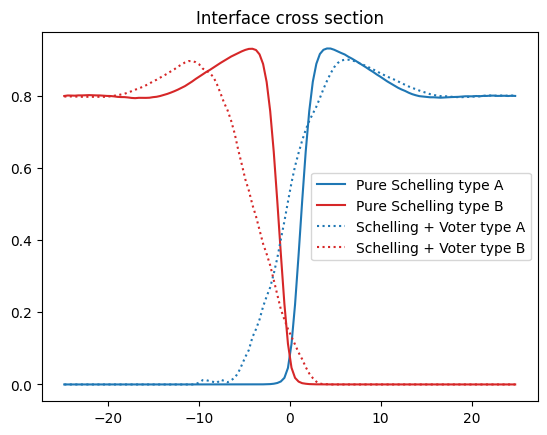

In [8]:
t_idx = -1

plt.plot(x, Crosssec_Schelling[0,t_idx], color = "tab:blue", label = "Pure Schelling type A" )
plt.plot(x, Crosssec_Schelling[1,t_idx], color = "tab:red" , label = "Pure Schelling type B")

plt.plot(x, Crosssec_SchellingVoter[0,t_idx], color = "tab:blue", ls = ":", label = "Schelling + Voter type A")
plt.plot(x, Crosssec_SchellingVoter[1,t_idx], color = "tab:red", ls = ":", label = "Schelling + Voter type B")

plt.title("Interface cross section")
plt.legend()
plt.show()

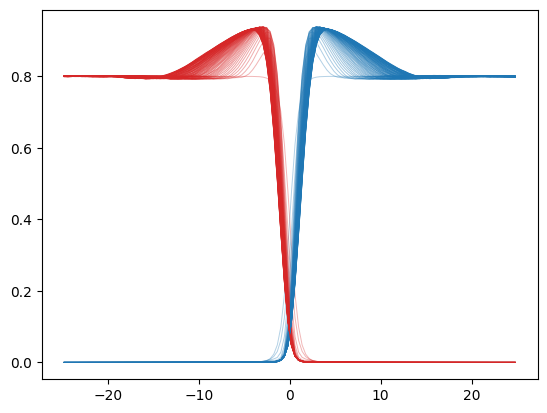

In [9]:
timestamps = np.linspace(0,500,51, dtype=int)
alphas = 1/3+timestamps/750

for i, t_idx in enumerate(timestamps):
    plt.plot(x, Crosssec_Schelling[0,t_idx], color = "tab:blue", lw =0.7, alpha = alphas[i] )
    plt.plot(x, Crosssec_Schelling[1,t_idx], color = "tab:red", lw = 0.7, alpha = alphas[i])

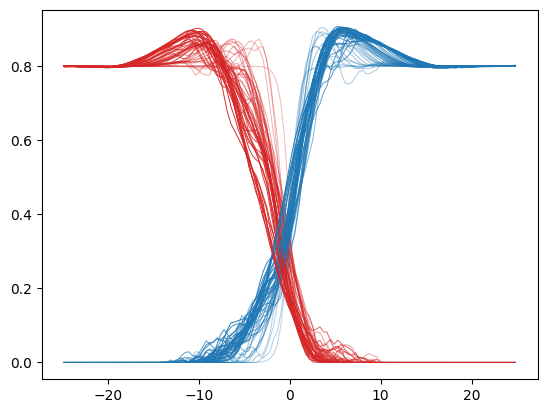

In [10]:
timestamps = np.linspace(0,500,51, dtype=int)

alphas = 1/3+timestamps/750

for i, t_idx in enumerate(timestamps):
    plt.plot(x, Crosssec_SchellingVoter[0,t_idx], color = "tab:blue", lw =0.7, alpha = alphas[i] )
    plt.plot(x, Crosssec_SchellingVoter[1,t_idx], color = "tab:red", lw = 0.7, alpha = alphas[i])

# Density of interfaces through time

In [11]:
rho_I_Sch = fhd.voter_interface_density(phi_run)
rho_I_Vot = fhd.voter_interface_density(phi_run_vot)

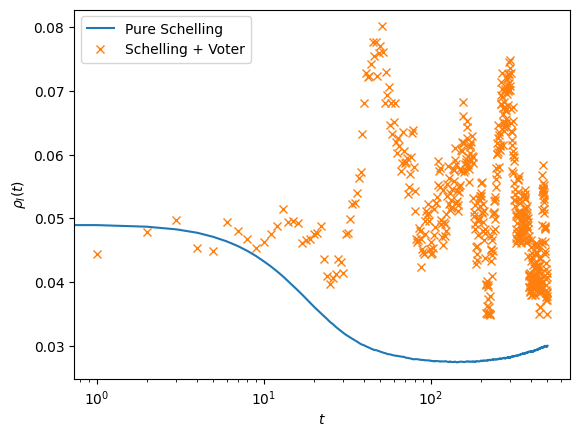

In [12]:
times = np.arange(len(rho_I_Sch)) * nsteps * dt / frames

plt.plot(times, rho_I_Sch,  label = "Pure Schelling")
plt.plot(times, rho_I_Vot, "x", label = "Schelling + Voter")
plt.ylabel(r"$\rho_I(t)$")
plt.xlabel(r"$t$")
plt.xscale("log")
plt.legend()
plt.show()
